# Análise das entradas: menos medidas, PCA e LDA como entrada (8 espécies)

Na apresentação, a banca fez duas perguntas sobre as entradas da rede:

1. a LDA foi usada só para explorar os dados; **por que não usar a LDA como entrada?**
2. se o resultado já é bom com 5 medidas, **o que acontece com menos entradas?**

As duas são a mesma pergunta vista de dois lados: reduzir a entrada **escolhendo** medidas
(seleção) ou **combinando** medidas (projeção). Este notebook mede as duas, e na projeção
compara a LDA com o PCA, como no exercício E11 da disciplina: o PCA procura as direções de
maior variância, sem olhar os rótulos; a LDA procura as que mais separam as espécies.

Regras:

- a rede e o treino são os da configuração final (notebook `10`): 1 camada oculta de 8
  neurônios com tanh, entropia cruzada com peso por classe, Adam com passo 0,01, mini-batch
  64, até 1000 épocas, pesos da época de menor perda de validação, sementes 0, 1 e 2.
  **Só muda o que entra na rede**;
- as Partes 1 e 2 comparam tudo **na validação**. O conjunto de teste só aparece na Parte 3,
  uma única vez, para a variante escolhida pela validação;
- o modelo final do trabalho (5 medidas) não é alterado.

In [1]:
import copy
import itertools
import json
import os

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

In [2]:
# Fixando seeds para poder reproduzir os resultados
np.random.seed(42)
torch.manual_seed(42)

# Dados já preparados no notebook 02: mesma limpeza, mesma divisão e mesma normalização do notebook 10
dados = np.load("../dados_processados/etapa2.npz", allow_pickle=True)

# Entradas já normalizadas com a média e o desvio do treino
X_np = dados["X_simples"].astype(np.float32)
MEDIDAS = ["Fmin", "Fmax", "Banda", "FME", "Duração"]  # Banda = Fmax − Fmin

# Rótulo: número da espécie, da mais para a menos frequente (0 = Myotis lavali)
ESPECIES = ["Myotis_lavali", "Molossus_molossus", "Lasiurus_blossevillii", "Neoeptesicus_furinalis",
            "Eumops_sp", "Molossus_currentium", "Molossops_temminckii", "Myotis_nigricans"]
N_classes = len(ESPECIES)
d_np = np.array([ESPECIES.index(e) for e in dados["y_simples"]])

# Posições de treino, validação e teste (o teste só é usado na Parte 3)
pos_tr = dados["pos_treino_simples"]
pos_va = dados["pos_val_simples"]
pos_te = dados["pos_teste_simples"]

dtr = torch.tensor(d_np[pos_tr]).type(torch.LongTensor)
dva = torch.tensor(d_np[pos_va]).type(torch.LongTensor)
dte = torch.tensor(d_np[pos_te]).type(torch.LongTensor)
Ntr = len(pos_tr)

print("Gravações:", X_np.shape[0], "| treino:", len(pos_tr), "| validação:", len(pos_va), "| teste:", len(pos_te))

Gravações: 13408 | treino: 9386 | validação: 2011 | teste: 2011


## Rede e treino

Os mesmos do notebook `10`. A única diferença é que o número de entradas da rede deixa de ser
fixo em 5: ele vem de quantas colunas a rede recebe.

In [3]:
# Ajuste de hiperparâmetros

# passo de adaptação
eta = 0.01

# Tamanho do mini-batch
Nb = 64

# Número de épocas
Ne = 1000

# Sementes dos três treinos
sementes = [0, 1, 2]

# Peso de cada espécie na função custo: inverso da frequência no treino
contagem_treino = np.bincount(d_np[pos_tr], minlength=N_classes)
pesos = Ntr / (N_classes * contagem_treino)

# Entropia cruzada categórica com peso por classe
loss_function = nn.CrossEntropyLoss(weight=torch.tensor(pesos, dtype=torch.float32))

In [4]:
class Model(nn.Module):
    # N_entradas: quantas entradas a rede recebe
    def __init__(self, N_entradas):
        # Necessário chamar __init__() da classe mãe
        super().__init__()

        self.model = nn.Sequential(
            # Entradas conectadas a 8 neurônios
            nn.Linear(N_entradas, 8),
            # Função de ativação tangente hiperbólica
            nn.Tanh(),
            # Saídas dos 8 neurônios conectadas a 8 neurônios de saída (um por espécie)
            nn.Linear(8, N_classes),
        )

    def forward(self, x):
        output = self.model(x)
        return output

In [5]:
# Treina uma rede com as entradas dadas (arrays do NumPy, já normalizados) e devolve o
# modelo com os pesos da época de menor perda de validação. É o mesmo loop do notebook 10.
def treina_rede(Xtr_np, Xva_np, semente):
    Xtr = torch.tensor(Xtr_np, dtype=torch.float32)
    Xva = torch.tensor(Xva_np, dtype=torch.float32)
    train_set = [(Xtr[i, :], dtr[i]) for i in range(Xtr.shape[0])]

    # A semente define a inicialização dos pesos...
    torch.manual_seed(semente)
    model = Model(Xtr.shape[1])
    optimizer = torch.optim.Adam(model.parameters(), lr=eta)

    # ...e a ordem dos mini-batches
    torch.manual_seed(semente)
    train_loader = torch.utils.data.DataLoader(train_set, batch_size=Nb, shuffle=True)

    melhor_val_loss = float("inf")
    melhores_pesos = None
    melhor_epoca = -1

    # Loop das épocas
    for epoch in range(Ne):
        # Coloca o modelo em modo treinamento
        model.train()

        # Loop dos mini-batches
        for X, d in train_loader:
            # Zera informações de gradientes
            model.zero_grad()
            # Calcula a saída
            y = model(X)
            # Calcula o valor da função custo
            loss = loss_function(y, d)
            # Calcula os gradientes
            loss.backward()
            # Atualiza os pesos do modelo
            optimizer.step()

        # Validação: modelo em modo de inferência e sem cálculo de gradientes
        model.eval()
        with torch.no_grad():
            y_val = model(Xva)
            val_loss = loss_function(y_val, dva)

        # Guarda os pesos se esta for a menor perda de validação até agora
        if val_loss.item() < melhor_val_loss:
            melhor_val_loss = val_loss.item()
            melhores_pesos = copy.deepcopy(model.state_dict())
            melhor_epoca = epoch + 1

    # Volta para os pesos da época de menor perda de validação
    model.load_state_dict(melhores_pesos)
    model.eval()
    return model, melhor_epoca

## Medidas de desempenho

As mesmas funções do notebook `10`: matriz de confusão com linha = espécie prevista e
coluna = espécie verdadeira, e a partir dela a acurácia balanceada (média das
sensibilidades) e o F1 macro.

In [6]:
# Espécie prevista: a de maior probabilidade na saída
def prever(model, X_entrada):
    model.eval()
    with torch.no_grad():
        y = model(torch.tensor(X_entrada, dtype=torch.float32))
        prob = torch.softmax(y, dim=1)
        _, predito = torch.max(prob, 1)
    return predito.numpy()


# Matriz de confusão: linha = espécie prevista, coluna = espécie verdadeira
def matriz_confusao(d, predito):
    M = np.zeros((N_classes, N_classes), dtype=int)
    for i in range(len(d)):
        M[predito[i], d[i]] += 1
    return M


# Medidas de desempenho calculadas a partir da matriz de confusão
def medidas(M):
    sens = np.zeros(N_classes)
    prec = np.zeros(N_classes)
    f1 = np.zeros(N_classes)
    for k in range(N_classes):
        VP = M[k, k]
        # sensibilidade: das gravações da espécie k, quantas foram achadas
        sens[k] = VP / M[:, k].sum()
        # precisão: das vezes em que o modelo disse k, quantas estavam certas
        if M[k, :].sum() > 0:
            prec[k] = VP / M[k, :].sum()
        if prec[k] + sens[k] > 0:
            f1[k] = 2 * prec[k] * sens[k] / (prec[k] + sens[k])
    acuracia_balanceada = sens.mean()
    f1_macro = f1.mean()
    acuracia = np.trace(M) / M.sum()
    return acuracia_balanceada, f1_macro, acuracia, sens, prec

## PCA e LDA

As duas projeções são calculadas **só com os dados de treino**. Na LDA isso é obrigatório:
ela usa os rótulos, e ajustá-la na base inteira levaria informação da validação e do teste
para a entrada da rede.

As duas usam as 4 medidas independentes. A largura de banda fica fora porque é
Fmax − Fmin: com ela, $S_W$ não tem inversa e o PCA teria uma direção de variância nula.
Com 4 medidas existem no máximo 4 direções.

- **PCA** (Slides_PCA): autovetores da matriz de covariância das entradas normalizadas.
- **LDA** (Slides_LDA): autovetores de $S_W^{-1} S_B$, em que $S_W$ é a dispersão dentro das
  classes e $S_B$ a dispersão entre as classes.

In [7]:
# Colunas usadas nas projeções: Fmin, Fmax, FME e Duração (sem a Banda)
COLUNAS_PROJ = [0, 1, 3, 4]
Xtr_proj = X_np[pos_tr][:, COLUNAS_PROJ].astype(np.float64)
dtr_np = d_np[pos_tr]
Nc = Xtr_proj.shape[1]

# ---------- PCA ----------
# matriz de covariância dos dados de treino
S = np.cov(Xtr_proj, rowvar=False, bias=True)

# autovalores e autovetores (S é simétrica), do maior para o menor
lb_pca, u_pca = np.linalg.eigh(S)
idx = np.argsort(lb_pca)[::-1]
lb_pca = lb_pca[idx]
u_pca = u_pca[:, idx]

var_explicada = lb_pca / np.sum(lb_pca)
var_acumulada = np.cumsum(var_explicada)
print("PCA - variância explicada (%):", np.round(100 * var_explicada, 1))
print("PCA - variância acumulada (%):", np.round(100 * var_acumulada, 1))

# ---------- LDA ----------
media_geral = Xtr_proj.mean(axis=0)
Sw = np.zeros((Nc, Nc))  # dispersão dentro das classes
Sb = np.zeros((Nc, Nc))  # dispersão entre as classes

for k in range(N_classes):
    Xk = Xtr_proj[dtr_np == k]
    media_k = Xk.mean(axis=0)
    Sw += (Xk - media_k).T @ (Xk - media_k)
    dif = (media_k - media_geral).reshape(-1, 1)
    Sb += len(Xk) * (dif @ dif.T)

# autovalores e autovetores de Sw^-1 Sb, do maior para o menor
lb_lda, u_lda = np.linalg.eig(np.linalg.inv(Sw) @ Sb)
idx = np.argsort(lb_lda.real)[::-1]
lb_lda = lb_lda.real[idx]
u_lda = u_lda.real[:, idx]

print("LDA - autovalores:", np.round(lb_lda, 2))
print("LDA - fração acumulada:", np.round(np.cumsum(lb_lda) / np.sum(lb_lda), 3))

PCA - variância explicada (%): [73.6 21.6  4.5  0.3]
PCA - variância acumulada (%): [ 73.6  95.2  99.7 100. ]
LDA - autovalores: [1.612e+01 9.900e-01 6.100e-01 1.000e-02]
LDA - fração acumulada: [0.909 0.965 0.999 1.   ]


In [8]:
# Devolve as entradas (matriz completa, todas as gravações) para um nome como
# 'Fmin+FME' (escolha de medidas), 'LDA 2' ou 'PCA 3' (projeção nas primeiras direções)
def entradas(nome):
    if nome.startswith("LDA ") or nome.startswith("PCA "):
        M_dir = int(nome.split()[1])
        if nome.startswith("LDA"):
            U_M = u_lda[:, 0:M_dir]
        else:
            U_M = u_pca[:, 0:M_dir]
        # projeção dos dados nas M primeiras direções
        P = X_np[:, COLUNAS_PROJ].astype(np.float64) @ U_M
        # normalização com média e desvio do treino
        P = (P - P[pos_tr].mean(axis=0)) / P[pos_tr].std(axis=0)
        return P.astype(np.float32)
    colunas = [MEDIDAS.index(m) for m in nome.split("+")]
    return X_np[:, colunas]

## Como cada entrada é avaliada

Para cada entrada, três treinos (sementes 0, 1 e 2), medidos na validação. Os resultados
ficam guardados em `dados_processados/etapa_f_resultados.json`, para o notebook não precisar
refazer os 117 treinos a cada execução (cada um leva cerca de 3 minutos).

In [9]:
CACHE = "../dados_processados/etapa_f_resultados.json"
if os.path.exists(CACHE):
    resultados = json.load(open(CACHE, encoding="utf-8"))
else:
    resultados = {}


# Treina as 3 sementes (ou lê o que já está guardado) e devolve a média na validação
def avalia(nome):
    P = entradas(nome)
    for semente in sementes:
        chave = f"{nome}|{semente}"
        if chave not in resultados:
            model, melhor_epoca = treina_rede(P[pos_tr], P[pos_va], semente)
            M = matriz_confusao(d_np[pos_va], prever(model, P[pos_va]))
            ab, f1, acc, sens, prec = medidas(M)
            resultados[chave] = {"ab": float(ab), "f1": float(f1), "sens": sens.round(4).tolist(), "epoca": melhor_epoca}
            json.dump(resultados, open(CACHE, "w", encoding="utf-8"), ensure_ascii=False, indent=0)
    ab = np.array([resultados[f"{nome}|{s}"]["ab"] for s in sementes])
    f1 = np.array([resultados[f"{nome}|{s}"]["f1"] for s in sementes])
    sens = np.mean([resultados[f"{nome}|{s}"]["sens"] for s in sementes], axis=0)
    return ab.mean(), ab.std(), f1.mean(), sens

## Parte 1 — Menos medidas: todas as combinações

Com 5 medidas existem 31 combinações não vazias. Em vez de escolher algumas, a rede é
treinada com **todas** (3 sementes cada, 93 treinos). Assim nenhuma combinação é
favorecida pela ordem em que foi testada.

In [10]:
# Todas as combinações, da maior para a menor
combinacoes = []
for n in range(5, 0, -1):
    for comb in itertools.combinations(MEDIDAS, n):
        combinacoes.append("+".join(comb))

selecao = {}
for nome in combinacoes:
    selecao[nome] = avalia(nome)

# Resultado com as 5 medidas (configuração final), usado como referência
AB_5 = selecao["Fmin+Fmax+Banda+FME+Duração"][0]
print(f"5 medidas (configuração final): {AB_5:.3f}\n")

print(f"{'entradas':30s} {'n':>2s} {'ac. balanceada':>15s} {'desvio':>7s} {'F1 macro':>9s} {'dif. para as 5':>15s}")
for n in range(5, 0, -1):
    do_tamanho = [nome for nome in combinacoes if nome.count("+") + 1 == n]
    # da melhor para a pior dentro de cada tamanho
    do_tamanho.sort(key=lambda nome: selecao[nome][0], reverse=True)
    for nome in do_tamanho:
        ab, desvio, f1, sens = selecao[nome]
        print(f"{nome:30s} {n:2d} {ab:15.3f} {desvio:7.3f} {f1:9.3f} {ab - AB_5:+15.3f}")

5 medidas (configuração final): 0.966

entradas                        n  ac. balanceada  desvio  F1 macro  dif. para as 5
Fmin+Fmax+Banda+FME+Duração     5           0.966   0.002     0.922          +0.000
Fmin+Fmax+Banda+FME             4           0.967   0.000     0.924          +0.001
Fmin+Banda+FME+Duração          4           0.966   0.001     0.926          +0.000
Fmax+Banda+FME+Duração          4           0.966   0.002     0.924          -0.000
Fmin+Fmax+FME+Duração           4           0.966   0.001     0.926          -0.001
Fmin+Fmax+Banda+Duração         4           0.932   0.004     0.862          -0.035
Fmin+Fmax+FME                   3           0.969   0.002     0.930          +0.002
Fmin+Banda+FME                  3           0.966   0.001     0.927          +0.000
Fmax+Banda+FME                  3           0.966   0.002     0.922          +0.000
Fmax+FME+Duração                3           0.959   0.001     0.909          -0.007
Banda+FME+Duração               3    

### Tirando uma medida por vez

Quanto muda a acurácia balanceada quando uma medida sai e as outras quatro ficam.

In [11]:
print(f"{'medida retirada':16s} {'ac. balanceada':>15s} {'desvio':>7s} {'dif. para as 5':>15s}")
for medida in MEDIDAS:
    resto = "+".join([m for m in MEDIDAS if m != medida])
    ab, desvio, f1, sens = selecao[resto]
    print(f"{medida:16s} {ab:15.3f} {desvio:7.3f} {ab - AB_5:+15.3f}")

medida retirada   ac. balanceada  desvio  dif. para as 5
Fmin                       0.966   0.002          -0.000
Fmax                       0.966   0.001          +0.000
Banda                      0.966   0.001          -0.001
FME                        0.932   0.004          -0.035
Duração                    0.967   0.000          +0.001


**Leitura.** A FME é a única medida que faz falta: sem ela a acurácia balanceada cai
0,035. Tirar a Fmin, a Fmax, a banda ou a duração não muda o resultado (diferenças menores
que a variação entre sementes). A banda é Fmax − Fmin, então a rede já tem essa informação;
a duração não acrescenta nada quando as frequências estão presentes.

### A melhor combinação de cada tamanho

In [12]:
melhores = {}
for n in range(5, 0, -1):
    do_tamanho = [nome for nome in combinacoes if nome.count("+") + 1 == n]
    melhores[n] = max(do_tamanho, key=lambda nome: selecao[nome][0])

print(f"{'n':>2s}  {'entradas':30s} {'ac. balanceada':>15s} {'desvio':>7s} {'F1 macro':>9s} {'dif. para as 5':>15s}")
for n in range(5, 0, -1):
    ab, desvio, f1, sens = selecao[melhores[n]]
    print(f"{n:2d}  {melhores[n]:30s} {ab:15.3f} {desvio:7.3f} {f1:9.3f} {ab - AB_5:+15.3f}")

 n  entradas                        ac. balanceada  desvio  F1 macro  dif. para as 5
 5  Fmin+Fmax+Banda+FME+Duração              0.966   0.002     0.922          +0.000
 4  Fmin+Fmax+Banda+FME                      0.967   0.000     0.924          +0.001
 3  Fmin+Fmax+FME                            0.969   0.002     0.930          +0.002
 2  Fmax+FME                                 0.956   0.002     0.904          -0.010
 1  Fmin                                     0.816   0.002     0.721          -0.150


**Leitura.** Com 3 medidas (Fmin, Fmax e FME) o resultado fica dentro de ±0,005 das 5
medidas, ou seja, empata. O valor um pouco maior (0,969) não significa que 3 medidas sejam
melhores: `Fmin+Banda+FME` e `Fmax+Banda+FME` carregam a mesma informação e dão 0,966.
Com 2 medidas o resultado sai do empate (−0,010) e com 1 cai muito.

### Quem sofre quando a entrada diminui

Sensibilidade por espécie (média das 3 sementes) na melhor combinação de cada tamanho.

In [13]:
print(f"{'espécie':24s}" + "".join([f"{n:>9d}" for n in range(5, 0, -1)]) + "   (número de medidas)")
for k in range(N_classes):
    linha = f"{ESPECIES[k]:24s}"
    for n in range(5, 0, -1):
        linha += f"{selecao[melhores[n]][3][k]:9.3f}"
    print(linha)

espécie                         5        4        3        2        1   (número de medidas)
Myotis_lavali               0.941    0.942    0.950    0.925    0.836
Molossus_molossus           0.927    0.922    0.928    0.915    0.447
Lasiurus_blossevillii       0.975    0.971    0.973    0.971    0.656
Neoeptesicus_furinalis      0.943    0.943    0.945    0.923    0.895
Eumops_sp                   0.997    1.000    1.000    0.997    1.000
Molossus_currentium         0.984    0.981    0.975    0.969    0.906
Molossops_temminckii        0.984    0.988    0.988    0.964    0.865
Myotis_nigricans            0.977    0.989    0.989    0.983    0.920


## Parte 2 — Projeções como entrada: LDA e PCA

A rede recebe as $M$ primeiras direções ($M$ = 1 a 4) em vez das medidas.

In [14]:
projecoes = {}
for metodo in ["LDA", "PCA"]:
    for M_dir in range(1, 5):
        nome = f"{metodo} {M_dir}"
        projecoes[nome] = avalia(nome)

print(f"{'entradas':10s} {'ac. balanceada':>15s} {'desvio':>7s} {'F1 macro':>9s} {'dif. para as 5':>15s}")
for nome in projecoes:
    ab, desvio, f1, sens = projecoes[nome]
    print(f"{nome:10s} {ab:15.3f} {desvio:7.3f} {f1:9.3f} {ab - AB_5:+15.3f}")

entradas    ac. balanceada  desvio  F1 macro  dif. para as 5
LDA 1                0.831   0.001     0.748          -0.135
LDA 2                0.924   0.001     0.873          -0.042
LDA 3                0.963   0.004     0.919          -0.003
LDA 4                0.964   0.002     0.925          -0.002
PCA 1                0.703   0.003     0.582          -0.264
PCA 2                0.787   0.000     0.694          -0.179
PCA 3                0.945   0.003     0.881          -0.021
PCA 4                0.965   0.001     0.921          -0.001


**Leitura.** Com as 4 direções, a LDA e o PCA empatam com as medidas originais: é a
mesma informação, só combinada de outro jeito, e a primeira camada da rede já faz
combinações lineares. Com poucas direções a LDA é bem melhor que o PCA (0,924 contra 0,787
com duas): as duas primeiras componentes do PCA explicam 95% da variância, mas variar muito
não é o mesmo que separar espécies.

## Seleção × LDA × PCA, pelo número de entradas

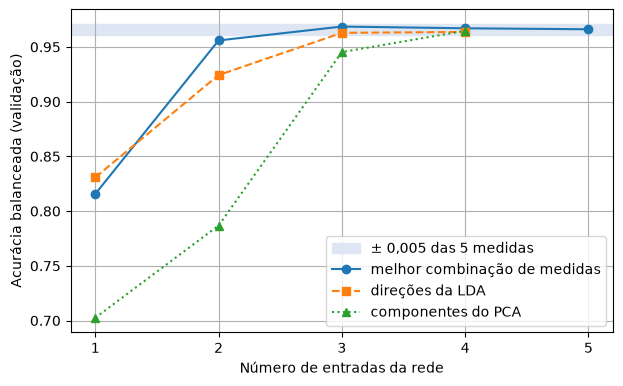

 n  melhor combinação     LDA     PCA   medidas
 1              0.816   0.831   0.703   Fmin
 2              0.956   0.924   0.787   Fmax+FME
 3              0.969   0.963   0.945   Fmin+Fmax+FME
 4              0.967   0.964   0.965   Fmin+Fmax+Banda+FME
 5              0.966       -       -   Fmin+Fmax+Banda+FME+Duração


In [15]:
n_entradas = [1, 2, 3, 4, 5]
ab_selecao = [selecao[melhores[n]][0] for n in n_entradas]
ab_lda = [projecoes[f"LDA {M_dir}"][0] for M_dir in range(1, 5)]
ab_pca = [projecoes[f"PCA {M_dir}"][0] for M_dir in range(1, 5)]

plt.figure(figsize=(7, 4.2))
plt.axhspan(AB_5 - 0.005, AB_5 + 0.005, color="#dfe6f3")
plt.plot(n_entradas, ab_selecao, "o-")
plt.plot([1, 2, 3, 4], ab_lda, "s--")
plt.plot([1, 2, 3, 4], ab_pca, "^:")
plt.legend(["± 0,005 das 5 medidas", "melhor combinação de medidas", "direções da LDA", "componentes do PCA"])
plt.xticks(n_entradas)
plt.xlabel("Número de entradas da rede")
plt.ylabel("Acurácia balanceada (validação)")
plt.grid(True)
plt.show()

print(f"{'n':>2s} {'melhor combinação':>18s} {'LDA':>7s} {'PCA':>7s}   medidas")
for n in n_entradas:
    lda_txt = f"{ab_lda[n - 1]:7.3f}" if n <= 4 else f"{'-':>7s}"
    pca_txt = f"{ab_pca[n - 1]:7.3f}" if n <= 4 else f"{'-':>7s}"
    print(f"{n:2d} {ab_selecao[n - 1]:18.3f} {lda_txt} {pca_txt}   {melhores[n]}")

**Leitura.** Com 2 e 3 entradas, escolher medidas dá resultado melhor que projetar com
a LDA. Uma hipótese (não testada): a LDA procura as direções que melhor separam as espécies
com fronteiras retas, e ao comprimir descarta informação que a camada oculta, que não é
linear, saberia usar. Para um sistema embarcado, a seleção tem outra vantagem: cada medida
retirada é uma medida que não precisa ser extraída do áudio; com a LDA ou o PCA, as 4 medidas
continuam sendo necessárias.

## Parte 3 — A variante de 3 medidas no teste

Pela validação, a menor entrada que empata com as 5 medidas é **Fmin, Fmax e FME**. Com a
escolha feita, essa variante é avaliada **uma única vez** no conjunto de teste, ao lado da
rede de 5 medidas (que reproduz o resultado do notebook `10`). Esta parte foi feita depois
da apresentação; o modelo final do trabalho continua sendo o de 5 medidas.

A rede de 3 medidas tem 3·8 + 8 + 8·8 + 8 = 104 parâmetros (a de 5 medidas tem 120).

In [16]:
variantes = ["Fmin+Fmax+Banda+FME+Duração", "Fmin+Fmax+FME"]
nomes_medidas = ["acurácia balanceada", "F1 macro", "acurácia"]

# Treina as duas variantes com as 3 sementes
modelos = {}
for nome in variantes:
    P = entradas(nome)
    for semente in sementes:
        model, melhor_epoca = treina_rede(P[pos_tr], P[pos_va], semente)
        modelos[(nome, semente)] = model
        print(f"{nome} - semente {semente}: pesos da época {melhor_epoca}")

Fmin+Fmax+Banda+FME+Duração - semente 0: pesos da época 818


Fmin+Fmax+Banda+FME+Duração - semente 1: pesos da época 339


Fmin+Fmax+Banda+FME+Duração - semente 2: pesos da época 438


Fmin+Fmax+FME - semente 0: pesos da época 741


Fmin+Fmax+FME - semente 1: pesos da época 445


Fmin+Fmax+FME - semente 2: pesos da época 926


In [17]:
sens_teste = {}
prec_teste = {}
erro_principal = {}

for nome in variantes:
    P = entradas(nome)
    for conjunto, pos in [("validação", pos_va), ("teste", pos_te)]:
        valores = np.zeros((len(sementes), 3))
        sens_s = []
        prec_s = []
        lavali_nigricans = []
        for s in range(len(sementes)):
            M = matriz_confusao(d_np[pos], prever(modelos[(nome, sementes[s])], P[pos]))
            ab, f1, acc, sens, prec = medidas(M)
            valores[s, :] = [ab, f1, acc]
            sens_s.append(sens)
            prec_s.append(prec)
            # Myotis lavali (coluna 0) chamado de Myotis nigricans (linha 7)
            lavali_nigricans.append(M[7, 0])
        print(f"{nome} - {conjunto}")
        for j in range(3):
            print(f"   {nomes_medidas[j]}: {valores[:, j].mean():.3f} ± {valores[:, j].std():.4f}")
        if conjunto == "teste":
            sens_teste[nome] = np.mean(sens_s, axis=0)
            prec_teste[nome] = np.mean(prec_s, axis=0)
            erro_principal[nome] = np.mean(lavali_nigricans)

print("\nNo teste, por espécie (média das 3 sementes):")
print(f"{'espécie':24s} {'sens. 5':>8s} {'sens. 3':>8s} {'prec. 5':>8s} {'prec. 3':>8s}")
for k in range(N_classes):
    print(f"{ESPECIES[k]:24s} {sens_teste[variantes[0]][k]:8.3f} {sens_teste[variantes[1]][k]:8.3f} "
          f"{prec_teste[variantes[0]][k]:8.3f} {prec_teste[variantes[1]][k]:8.3f}")
print(f"\nMyotis lavali chamado de Myotis nigricans: {erro_principal[variantes[0]]:.1f} (5 medidas) "
      f"e {erro_principal[variantes[1]]:.1f} (3 medidas)")

Fmin+Fmax+Banda+FME+Duração - validação
   acurácia balanceada: 0.966 ± 0.0019
   F1 macro: 0.922 ± 0.0044
   acurácia: 0.950 ± 0.0030
Fmin+Fmax+Banda+FME+Duração - teste
   acurácia balanceada: 0.959 ± 0.0002
   F1 macro: 0.926 ± 0.0048
   acurácia: 0.955 ± 0.0038
Fmin+Fmax+FME - validação
   acurácia balanceada: 0.969 ± 0.0020
   F1 macro: 0.930 ± 0.0009
   acurácia: 0.956 ± 0.0004
Fmin+Fmax+FME - teste
   acurácia balanceada: 0.959 ± 0.0011
   F1 macro: 0.929 ± 0.0025
   acurácia: 0.958 ± 0.0016

No teste, por espécie (média das 3 sementes):
espécie                   sens. 5  sens. 3  prec. 5  prec. 3
Myotis_lavali               0.956    0.965    0.996    0.996
Molossus_molossus           0.928    0.915    0.979    0.983
Lasiurus_blossevillii       0.957    0.951    0.921    0.923
Neoeptesicus_furinalis      0.936    0.941    0.936    0.905
Eumops_sp                   0.985    0.976    0.964    0.970
Molossus_currentium         0.963    0.969    0.897    0.908
Molossops_temminckii  

## Conclusões

- **Menos entradas:** três medidas (Fmin, Fmax e FME) dão o mesmo resultado que as cinco, na
  validação e no teste. A largura de banda e a duração são dispensáveis.
- **A FME é a única medida insubstituível**, o que concorda com a chave dos especialistas,
  baseada na FME. Mas ela sozinha não basta (0,799 na validação): precisa das frequências
  mínima e máxima.
- **LDA ou PCA como entrada não melhoram o modelo.** Com todas as direções empatam; com
  menos, perdem para a simples escolha de medidas.
- **Sistema embarcado:** a rede de 3 medidas tem 104 parâmetros e dispensa a medição da
  duração do pulso. A extração das medidas a partir do áudio não foi feita neste trabalho.

O teste foi usado nesta parte só para medir a variante já escolhida pela validação; nenhuma
escolha foi feita olhando o teste, e o modelo final não foi alterado.